# Student Digital Life and Academic Performance Analysis

#### Project Objective

The objective of this project is to analyze how students' digital habits, lifestyle, and well-being are associated with their academic performance and academic failure risk.

The project applies the Python concepts learned throughout the course, including conditional statements, loops, functions, file handling, Pandas, NumPy, Matplotlib, and Seaborn.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
# Load the dataset

df = pd.read_csv("student_digital_life.csv")

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [9]:
# Display the first five records

df.head()

,Student_ID,Age,Gender,Education_Level,Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours,Sleep_Hours,Physical_Activity_Hours,Mental_Health_Score,Physical_Health_Score,Social_Isolation_Score,Burnout_Level,Academic_Performance_Score,Academic_Failure_Risk
0,STU_00001,19,Male,College,5.32,1.21,7.30,1.41,74.06,98.90,4.05,Low,88.80,0
1,STU_00002,16,Non-binary,High School,5.21,3.89,7.81,2.48,76.13,89.94,4.65,Moderate,50.60,0
2,STU_00003,25,Male,University,3.61,2.65,6.34,0.06,65.01,76.75,5.28,Low,96.67,0
3,STU_00004,23,Male,University,2.93,1.43,6.12,1.37,74.67,87.38,3.66,Low,85.65,0
4,STU_00005,20,Non-binary,College,6.52,1.64,5.23,1.14,67.74,88.04,3.25,Moderate,71.84,0


In [18]:
# Check the size of the dataset

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 15000
Columns: 14


In [16]:
# Display all column names

print("Dataset Columns:")

for column in df.columns:
    print(column)

Dataset Columns:
Student_ID
Age
Gender
Education_Level
Daily_Social_Media_Hours
Daily_AI_Tool_Usage_Hours
Sleep_Hours
Physical_Activity_Hours
Mental_Health_Score
Physical_Health_Score
Social_Isolation_Score
Burnout_Level
Academic_Performance_Score
Academic_Failure_Risk


In [17]:
# Check the data types

df.dtypes

Student_ID                     object
Age                             int64
Gender                         object
Education_Level                object
Daily_Social_Media_Hours      float64
Daily_AI_Tool_Usage_Hours     float64
Sleep_Hours                   float64
Physical_Activity_Hours       float64
Mental_Health_Score           float64
Physical_Health_Score         float64
Social_Isolation_Score        float64
Burnout_Level                  object
Academic_Performance_Score    float64
Academic_Failure_Risk           int64
dtype: object

In [19]:
# Display dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  15000 non-null  object 
 1   Age                         15000 non-null  int64  
 2   Gender                      15000 non-null  object 
 3   Education_Level             15000 non-null  object 
 4   Daily_Social_Media_Hours    15000 non-null  float64
 5   Daily_AI_Tool_Usage_Hours   15000 non-null  float64
 6   Sleep_Hours                 15000 non-null  float64
 7   Physical_Activity_Hours     15000 non-null  float64
 8   Mental_Health_Score         15000 non-null  float64
 9   Physical_Health_Score       15000 non-null  float64
 10  Social_Isolation_Score      15000 non-null  float64
 11  Burnout_Level               15000 non-null  object 
 12  Academic_Performance_Score  15000 non-null  float64
 13  Academic_Failure_Risk       150

In [20]:
# Check for missing values

print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Student_ID                    0
Age                           0
Gender                        0
Education_Level               0
Daily_Social_Media_Hours      0
Daily_AI_Tool_Usage_Hours     0
Sleep_Hours                   0
Physical_Activity_Hours       0
Mental_Health_Score           0
Physical_Health_Score         0
Social_Isolation_Score        0
Burnout_Level                 0
Academic_Performance_Score    0
Academic_Failure_Risk         0
dtype: int64


In [21]:
print("Total Missing Values:", df.isnull().sum().sum())

Total Missing Values: 0


In [22]:
# Check for duplicate records

duplicate_count = df.duplicated().sum()

print("Duplicate Records:", duplicate_count)

Duplicate Records: 0


In [23]:
# Check unique Student IDs

print("Total Records:", len(df))
print("Unique Student IDs:", df['Student_ID'].nunique())

Total Records: 15000
Unique Student IDs: 15000


In [28]:
# Create a simple data quality summary

quality_summary = pd.DataFrame({
    'Check': [
        'Total Records',
        'Total Columns',
        'Missing Values',
        'Duplicate Records',
        'Unique Student IDs'
    ],
    
    'Result': [
        len(df),
        len(df.columns),
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        df['Student_ID'].nunique()
    ]
})

quality_summary

,Check,Result
0,Total Records,15000
1,Total Columns,14
2,Missing Values,0
3,Duplicate Records,0
4,Unique Student IDs,15000


In [29]:
# Select important numerical columns

numerical_columns = [
    'Age',
    'Daily_Social_Media_Hours',
    'Daily_AI_Tool_Usage_Hours',
    'Sleep_Hours',
    'Physical_Activity_Hours',
    'Mental_Health_Score',
    'Physical_Health_Score',
    'Social_Isolation_Score',
    'Academic_Performance_Score'
]

df[numerical_columns].describe().round(2)

,Age,Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours,Sleep_Hours,Physical_Activity_Hours,Mental_Health_Score,Physical_Health_Score,Social_Isolation_Score,Academic_Performance_Score
count,15000.00,15000.00,15000.00,15000.00,15000.00,15000.00,15000.00,15000.00,15000.00
mean,19.04,4.54,2.58,6.54,1.25,72.51,88.02,4.31,78.31
std,3.77,2.40,1.68,1.27,1.04,9.25,9.68,1.16,11.54
min,13.00,0.00,0.00,2.00,0.00,32.56,48.03,0.97,23.99
25%,16.00,2.83,1.31,5.68,0.31,66.78,81.52,3.47,70.53
50%,19.00,4.50,2.51,6.55,1.13,73.76,89.47,4.28,78.59
75%,22.00,6.18,3.74,7.41,1.95,79.58,97.16,5.12,86.70
max,25.00,14.00,9.50,11.15,5.00,91.76,99.98,8.41,99.98


In [30]:
# Create a simple average student profile

average_profile = pd.DataFrame({
    'Measure': [
        'Age',
        'Social Media Use (Hours)',
        'AI Tool Use (Hours)',
        'Sleep (Hours)',
        'Physical Activity (Hours)',
        'Mental Health Score',
        'Physical Health Score',
        'Academic Performance Score'
    ],
    
    'Average': [
        df['Age'].mean(),
        df['Daily_Social_Media_Hours'].mean(),
        df['Daily_AI_Tool_Usage_Hours'].mean(),
        df['Sleep_Hours'].mean(),
        df['Physical_Activity_Hours'].mean(),
        df['Mental_Health_Score'].mean(),
        df['Physical_Health_Score'].mean(),
        df['Academic_Performance_Score'].mean()
    ]
})

average_profile['Average'] = average_profile['Average'].round(2)

average_profile

,Measure,Average
0,Age,19.04
1,Social Media Use (Hours),4.54
2,AI Tool Use (Hours),2.58
3,Sleep (Hours),6.54
4,Physical Activity (Hours),1.25
5,Mental Health Score,72.51
6,Physical Health Score,88.02
7,Academic Performance Score,78.31


#### Module 1 - Conditional Statement

In [32]:
%%writefile module1_condition.py

# Module 1: Conditional Statement -- Academic_Performance_Score

def performance_status(score):
    
    if score >= 85:
        return "High Performance"
    
    elif score >= 70:
        return "Moderate Performance"
    
    else:
        return "Low Performance"

Overwriting module1_condition.py


In [44]:
import module1_condition

In [34]:
# Calculate average academic performance

average_score = df['Academic_Performance_Score'].mean()

print("Average Academic Performance Score:", round(average_score, 2))

Average Academic Performance Score: 78.31


In [35]:
# Classify the average academic performance

performance_result = module1_condition.performance_status(average_score)

print("Overall Performance Status:", performance_result)

Overall Performance Status: Moderate Performance


#### Module 2 - Loop

In [37]:
%%writefile module2_loop.py

# Module 2: Loop Statement -- Burnout_Level

def count_burnout(burnout_data):
    
    low = 0
    moderate = 0
    high = 0
    severe = 0
    
    for level in burnout_data:
        
        if level == "Low":
            low += 1
            
        elif level == "Moderate":
            moderate += 1
            
        elif level == "High":
            high += 1
            
        elif level == "Severe":
            severe += 1
    
    return low, moderate, high, severe

Overwriting module2_loop.py


In [43]:
import module2_loop

In [39]:
# Count students in each burnout level using a loop

low, moderate, high, severe = module2_loop.count_burnout(
    df['Burnout_Level']
)

print("Low Burnout:", low)
print("Moderate Burnout:", moderate)
print("High Burnout:", high)
print("Severe Burnout:", severe)

Low Burnout: 9000
Moderate Burnout: 4200
High Burnout: 1350
Severe Burnout: 450


In [40]:
# Display burnout results in a table

burnout_summary = pd.DataFrame({
    'Burnout Level': ['Low', 'Moderate', 'High', 'Severe'],
    'Number of Students': [low, moderate, high, severe]
})

burnout_summary

,Burnout Level,Number of Students
0,Low,9000
1,Moderate,4200
2,High,1350
3,Severe,450


#### Module 3 - Function

In [41]:
%%writefile module3_function.py

# Module 3: Custom Function  --  Daily_Social_Media_Hours

def social_media_category(hours):
    
    if hours < 3:
        return "Low Usage"
    
    elif hours <= 6:
        return "Moderate Usage"
    
    else:
        return "High Usage"

Writing module3_function.py


In [42]:
import module3_function

In [45]:
# Create social media usage categories

df['Social_Media_Category'] = df['Daily_Social_Media_Hours'].apply(
    module3_function.social_media_category
)

df[['Daily_Social_Media_Hours', 'Social_Media_Category']].head()

,Daily_Social_Media_Hours,Social_Media_Category
0,5.32,Moderate Usage
1,5.21,Moderate Usage
2,3.61,Moderate Usage
3,2.93,Low Usage
4,6.52,High Usage


In [46]:
print("Number of Columns After Creating New Category:", df.shape[1])

Number of Columns After Creating New Category: 15


In [54]:
# Count students in each social media category

social_media_counts = df['Social_Media_Category'].value_counts().reset_index()

print(social_media_counts)

  Social_Media_Category  count
0        Moderate Usage   6858
1            High Usage   4072
2             Low Usage   4070


#### Module 4 - File I/O

In [55]:
%%writefile module4_file.py

# Module 4: File I/O

def save_report(report):
    
    file = open("student_analysis_report.txt", "w")
    
    file.write(report)
    
    file.close()

Writing module4_file.py


In [56]:
import module4_file

## Data Analysis

In [57]:
# Summary of students digital habits

digital_summary = df[
    ['Daily_Social_Media_Hours',
     'Daily_AI_Tool_Usage_Hours']
].describe().round(2)

digital_summary

,Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours
count,15000.00,15000.00
mean,4.54,2.58
std,2.40,1.68
min,0.00,0.00
25%,2.83,1.31
50%,4.50,2.51
75%,6.18,3.74
max,14.00,9.50


In [68]:
# Average academic performance by social media usage category

social_media_performance = df.groupby(
    'Social_Media_Category'
)['Academic_Performance_Score'].mean().round(2).reset_index()

social_media_performance

,Social_Media_Category,Academic_Performance_Score
0,High Usage,72.67
1,Low Usage,83.85
2,Moderate Usage,78.38


In [70]:
# Correlation between social media use and academic performance

social_media_corr = df[
    'Daily_Social_Media_Hours'
].corr(
    df['Academic_Performance_Score']
)

print(
    "Correlation between Social Media Use and Academic Performance:",
    round(social_media_corr, 2)
)

Correlation between Social Media Use and Academic Performance: -0.39


In [14]:
# Correlation between AI tool usage and academic performance

ai_corr = df[
    'Daily_AI_Tool_Usage_Hours'
].corr(
    df['Academic_Performance_Score']
)

print(
    "Correlation between AI Tool Usage and Academic Performance:",
    round(ai_corr, 2)
)

Correlation between AI Tool Usage and Academic Performance: -0.21


In [72]:
# Summary of lifestyle variables

lifestyle_summary = df[
    ['Sleep_Hours',
     'Physical_Activity_Hours']
].describe().round(2)

lifestyle_summary

,Sleep_Hours,Physical_Activity_Hours
count,15000.00,15000.00
mean,6.54,1.25
std,1.27,1.04
min,2.00,0.00
25%,5.68,0.31
50%,6.55,1.13
75%,7.41,1.95
max,11.15,5.00


In [73]:
# Correlation between sleep and academic performance

sleep_corr = df[
    'Sleep_Hours'
].corr(
    df['Academic_Performance_Score']
)

print(
    "Correlation between Sleep and Academic Performance:",
    round(sleep_corr, 2)
)

Correlation between Sleep and Academic Performance: 0.29


In [74]:
# Correlation between physical activity and academic performance

activity_corr = df[
    'Physical_Activity_Hours'
].corr(
    df['Academic_Performance_Score']
)

print(
    "Correlation between Physical Activity and Academic Performance:",
    round(activity_corr, 2)
)

Correlation between Physical Activity and Academic Performance: 0.04


In [75]:
# Summary of student well-being

wellbeing_summary = df[
    ['Mental_Health_Score',
     'Physical_Health_Score',
     'Social_Isolation_Score']
].describe().round(2)

wellbeing_summary

,Mental_Health_Score,Physical_Health_Score,Social_Isolation_Score
count,15000.00,15000.00,15000.00
mean,72.51,88.02,4.31
std,9.25,9.68,1.16
min,32.56,48.03,0.97
25%,66.78,81.52,3.47
50%,73.76,89.47,4.28
75%,79.58,97.16,5.12
max,91.76,99.98,8.41


In [80]:
# Relationship between well-being and academic performance

mental_corr = df[
    'Mental_Health_Score'
].corr(
    df['Academic_Performance_Score']
)

physical_health_corr = df[
    'Physical_Health_Score'
].corr(
    df['Academic_Performance_Score']
)

isolation_corr = df[
    'Social_Isolation_Score'
].corr(
    df['Academic_Performance_Score']
)

print("Mental Health Correlation:", round(mental_corr, 2))
print("Physical Health Correlation:", round(physical_health_corr, 2))
print("Social Isolation Correlation:", round(isolation_corr, 2))

Mental Health Correlation: 0.2
Physical Health Correlation: 0.15
Social Isolation Correlation: -0.23


In [ ]:
# Average academic performance by burnout level

burnout_order = [
    'Low',
    'Moderate',
    'High',
    'Severe'
]

burnout_performance_table = pd.DataFrame({
    'Burnout Level': burnout_order,
    'Average Academic Performance': [
        burnout_performance['Low'],
        burnout_performance['Moderate'],
        burnout_performance['High'],
        burnout_performance['Severe']
    ]
})

burnout_performance_table

,Burnout Level,Average Academic Performance
0,Low,80.86
1,Moderate,75.79
2,High,72.44
3,Severe,68.64


In [82]:
# Create a summary of relationships with academic performance

relationship_summary = pd.DataFrame({
    'Factor': [
        'Social Media Use',
        'AI Tool Usage',
        'Sleep',
        'Physical Activity',
        'Mental Health',
        'Physical Health',
        'Social Isolation'
    ],
    
    'Correlation with Academic Performance': [
        social_media_corr,
        ai_corr,
        sleep_corr,
        activity_corr,
        mental_corr,
        physical_health_corr,
        isolation_corr
    ]
})

relationship_summary[
    'Correlation with Academic Performance'
] = relationship_summary[
    'Correlation with Academic Performance'
].round(2)

relationship_summary

,Factor,Correlation with Academic Performance
0,Social Media Use,-0.39
1,AI Tool Usage,-0.21
2,Sleep,0.29
3,Physical Activity,0.04
4,Mental Health,0.20
5,Physical Health,0.15
6,Social Isolation,-0.23


#### Failure-risk distribution

In [83]:
# Count students by academic failure risk

failure_risk_count = df['Academic_Failure_Risk'].value_counts().sort_index()

print("No Failure Risk:", failure_risk_count[0])
print("Failure Risk:", failure_risk_count[1])

No Failure Risk: 14100
Failure Risk: 900


In [84]:
# Calculate academic failure risk percentage

failure_risk_percentage = (
    df['Academic_Failure_Risk'].value_counts(normalize=True)
    .sort_index() * 100
).round(2)

print("No Failure Risk:", failure_risk_percentage[0], "%")
print("Failure Risk:", failure_risk_percentage[1], "%")

No Failure Risk: 94.0 %
Failure Risk: 6.0 %


In [85]:
# Create academic failure risk summary

failure_risk_summary = pd.DataFrame({
    'Academic Status': [
        'No Failure Risk',
        'Failure Risk'
    ],
    
    'Number of Students': [
        failure_risk_count[0],
        failure_risk_count[1]
    ],
    
    'Percentage': [
        failure_risk_percentage[0],
        failure_risk_percentage[1]
    ]
})

failure_risk_summary

,Academic Status,Number of Students,Percentage
0,No Failure Risk,14100,94.0
1,Failure Risk,900,6.0


#### Compare failure-risk students with other students

In [86]:
# Compare important factors by academic failure risk

failure_risk_comparison = df.groupby(
    'Academic_Failure_Risk'
)[
    [
        'Daily_Social_Media_Hours',
        'Daily_AI_Tool_Usage_Hours',
        'Sleep_Hours',
        'Mental_Health_Score',
        'Social_Isolation_Score',
        'Academic_Performance_Score'
    ]
].mean().round(2)

failure_risk_comparison

,Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours,Sleep_Hours,Mental_Health_Score,Social_Isolation_Score,Academic_Performance_Score
Academic_Failure_Risk,,,,,,
0,4.34,2.53,6.62,73.34,4.24,79.18
1,7.67,3.51,5.35,59.49,5.37,64.79


## NumPy Analysis

NumPy is used to perform basic numerical analysis on the academic performance scores in the dataset.

In [87]:
# Convert academic performance scores to a NumPy array

academic_scores = df[
    'Academic_Performance_Score'
].to_numpy()

print(academic_scores)

[88.8  50.6  96.67 ... 89.84 65.44 92.91]


In [88]:
# Calculate statistics using NumPy

mean_score = np.mean(academic_scores)
median_score = np.median(academic_scores)
minimum_score = np.min(academic_scores)
maximum_score = np.max(academic_scores)
std_score = np.std(academic_scores)

print("Mean Score:", round(mean_score, 2))
print("Median Score:", round(median_score, 2))
print("Minimum Score:", round(minimum_score, 2))
print("Maximum Score:", round(maximum_score, 2))
print("Standard Deviation:", round(std_score, 2))

Mean Score: 78.31
Median Score: 78.59
Minimum Score: 23.99
Maximum Score: 99.98
Standard Deviation: 11.54


In [89]:
# Create NumPy analysis summary

numpy_summary = pd.DataFrame({
    'Statistic': [
        'Mean',
        'Median',
        'Minimum',
        'Maximum',
        'Standard Deviation'
    ],
    
    'Value': [
        mean_score,
        median_score,
        minimum_score,
        maximum_score,
        std_score
    ]
})

numpy_summary['Value'] = numpy_summary['Value'].round(2)

numpy_summary

,Statistic,Value
0,Mean,78.31
1,Median,78.59
2,Minimum,23.99
3,Maximum,99.98
4,Standard Deviation,11.54


In [90]:
# Create final analysis report

report = f"""
STUDENT DIGITAL LIFE AND ACADEMIC PERFORMANCE ANALYSIS
=====================================================

DATASET SUMMARY
---------------
Total Students: {len(df)}
Average Academic Performance: {mean_score:.2f}
Overall Performance Status: {performance_result}

DIGITAL HABITS
--------------
Average Social Media Usage: {df['Daily_Social_Media_Hours'].mean():.2f} hours/day
Average AI Tool Usage: {df['Daily_AI_Tool_Usage_Hours'].mean():.2f} hours/day

LIFESTYLE
---------
Average Sleep: {df['Sleep_Hours'].mean():.2f} hours/day
Average Physical Activity: {df['Physical_Activity_Hours'].mean():.2f} hours/day

BURNOUT
-------
Low: {low}
Moderate: {moderate}
High: {high}
Severe: {severe}

ACADEMIC FAILURE RISK
---------------------
Students at Failure Risk: {failure_risk_count[1]}
Failure Risk Percentage: {failure_risk_percentage[1]:.2f}%

KEY RELATIONSHIPS
-----------------
Social Media vs Academic Performance: {social_media_corr:.2f}
AI Usage vs Academic Performance: {ai_corr:.2f}
Sleep vs Academic Performance: {sleep_corr:.2f}
Physical Activity vs Academic Performance: {activity_corr:.2f}
Mental Health vs Academic Performance: {mental_corr:.2f}
Physical Health vs Academic Performance: {physical_health_corr:.2f}
Social Isolation vs Academic Performance: {isolation_corr:.2f}

MAIN FINDINGS
-------------
Higher social media usage was associated with lower academic performance.
Academic performance decreased as burnout severity increased.
More sleep was associated with higher academic performance.
Students at academic failure risk showed higher digital usage, lower sleep,
lower mental health, greater social isolation, and lower academic performance.

CONCLUSION
----------
The analysis suggests that students' academic performance is associated with
a combination of digital habits, lifestyle, and well-being factors.
"""

print(report)


STUDENT DIGITAL LIFE AND ACADEMIC PERFORMANCE ANALYSIS

DATASET SUMMARY
---------------
Total Students: 15000
Average Academic Performance: 78.31
Overall Performance Status: Moderate Performance

DIGITAL HABITS
--------------
Average Social Media Usage: 4.54 hours/day
Average AI Tool Usage: 2.58 hours/day

LIFESTYLE
---------
Average Sleep: 6.54 hours/day
Average Physical Activity: 1.25 hours/day

BURNOUT
-------
Low: 9000
Moderate: 4200
High: 1350
Severe: 450

ACADEMIC FAILURE RISK
---------------------
Students at Failure Risk: 900
Failure Risk Percentage: 6.00%

KEY RELATIONSHIPS
-----------------
Social Media vs Academic Performance: -0.39
AI Usage vs Academic Performance: -0.21
Sleep vs Academic Performance: 0.29
Physical Activity vs Academic Performance: 0.04
Mental Health vs Academic Performance: 0.20
Physical Health vs Academic Performance: 0.15
Social Isolation vs Academic Performance: -0.23

MAIN FINDINGS
-------------
Higher social media usage was associated with lower acad

In [91]:
# Save the final report using the File I/O module

module4_file.save_report(report)

print("Analysis report saved successfully.")

Analysis report saved successfully.


# Demographic Analysis

This section compares academic performance and digital habits across different age groups, genders, and education levels.

In [9]:
# Create age groups

df['Age_Group'] = pd.cut(
    df['Age'],
    bins=[12, 17, 21, 25],
    labels=['13-17', '18-21', '22-25']
)

In [10]:
# Compare age groups

age_summary = df.groupby(
    'Age_Group', observed=True
).agg(
    Students=('Student_ID', 'count'),
    Average_Performance=('Academic_Performance_Score', 'mean'),
    Social_Media_Hours=('Daily_Social_Media_Hours', 'mean'),
    Failure_Risk_Rate=('Academic_Failure_Risk', 'mean')
).round(2)

age_summary['Failure_Risk_Rate'] = (
    age_summary['Failure_Risk_Rate'] * 100
)

age_summary

,Students,Average_Performance,Social_Media_Hours,Failure_Risk_Rate
Age_Group,,,,
13-17,5693,78.46,4.56,6.0
18-21,4597,78.31,4.49,6.0
22-25,4710,78.14,4.56,7.0


In [11]:
# Compare gender groups

gender_summary = df.groupby('Gender').agg(
    Students=('Student_ID', 'count'),
    Average_Performance=('Academic_Performance_Score', 'mean'),
    Social_Media_Hours=('Daily_Social_Media_Hours', 'mean'),
    Failure_Risk_Rate=('Academic_Failure_Risk', 'mean')
)

gender_summary['Failure_Risk_Rate'] *= 100

gender_summary.round(2)

,Students,Average_Performance,Social_Media_Hours,Failure_Risk_Rate
Gender,,,,
Female,7143,78.45,4.55,6.08
Male,7265,78.20,4.53,6.00
Non-binary,592,78.07,4.50,5.07


In [12]:
# Compare education levels

education_summary = df.groupby('Education_Level').agg(
    Students=('Student_ID', 'count'),
    Average_Performance=('Academic_Performance_Score', 'mean'),
    Social_Media_Hours=('Daily_Social_Media_Hours', 'mean'),
    Failure_Risk_Rate=('Academic_Failure_Risk', 'mean')
)

education_summary['Failure_Risk_Rate'] *= 100

education_summary.round(2)

,Students,Average_Performance,Social_Media_Hours,Failure_Risk_Rate
Education_Level,,,,
College,4597,78.31,4.49,5.70
High School,5693,78.46,4.56,5.78
University,4710,78.14,4.56,6.56


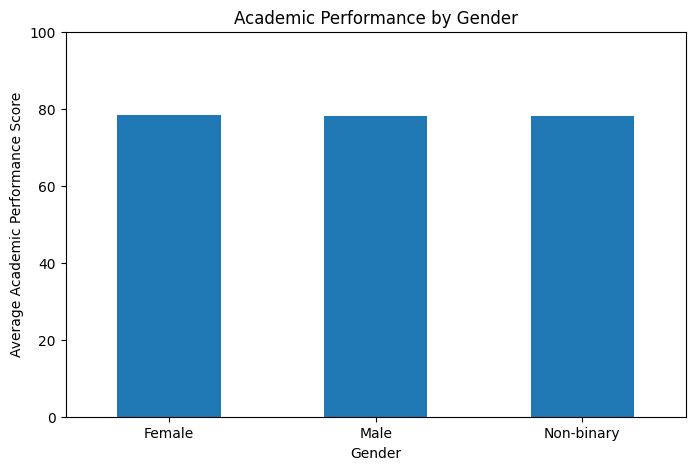

In [13]:
# Average academic performance by gender

gender_performance = df.groupby(
    'Gender'
)['Academic_Performance_Score'].mean()

plt.figure(figsize=(8, 5))

gender_performance.plot(kind='bar')

plt.title('Academic Performance by Gender')
plt.xlabel('Gender')
plt.ylabel('Average Academic Performance Score')
plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.show()